<a href="https://colab.research.google.com/github/STung25/ai4b-course2/blob/main/ML_Excercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os

try:                                    # are we in Google Colab?
    from google.colab import drive
    IN_COLAB = True
except ImportError:                     # the notebook also runs elsewhere, for tests
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/AI4B/course2"      # one folder per project
else:
    PROJECT = os.path.abspath("AI4B_course2")

for sub in ["data", "outputs"]:                          # same structure in every project
    os.makedirs(os.path.join(PROJECT, sub), exist_ok=True)

print("Project folder:", PROJECT)
print("It contains   :", os.listdir(PROJECT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/AI4B/course2
It contains   : ['data', 'outputs']


Question: You save a file in /content/result.csv. Where will it be tomorrow? And if you save it in PROJECT?
**Answer: Yes because it saved to my drive.**

In [7]:
REPO_URL = "https://github.com/mwaskom/seaborn-data.git"
REPO_DIR = "/content/seaborn-data" if IN_COLAB else os.path.abspath("seaborn-data")

if not os.path.exists(REPO_DIR):
    !git clone --depth 1 {REPO_URL} {REPO_DIR}      # first time: copy the latest version
else:
    !git -C {REPO_DIR} pull                         # next times: only get what changed

import pandas as pd
taxis = pd.read_csv(os.path.join(REPO_DIR, "taxis.csv"))     # real New York City taxi rides, March 2019
print(taxis.shape)
taxis.head()

Cloning into '/content/seaborn-data'...
remote: Enumerating objects: 59, done.
remote: Counting objects: 100% (59/59), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 59 (delta 1), reused 44 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (59/59), 4.83 MiB | 25.62 MiB/s, done.
Resolving deltas: 100% (1/1), done.
(6433, 14)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [8]:
print(taxis.groupby("payment")["tip"].agg(["count", "mean"]).round(2))
print("Cash rides with a recorded tip:", (taxis.loc[taxis.payment == "cash", "tip"] > 0).sum())

             count  mean
payment                 
cash          1812  0.00
credit card   4577  2.78
Cash rides with a recorded tip: 0


In [9]:
#====RAW DATA TO TRUSTED INDICATORS=======
URL = ("https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/"
       "master/data/retail-data/all/online-retail-dataset.csv")

raw = pd.read_csv(URL, dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [10]:
#====Audit: count the problems before fixing anything

audit = {
    "rows": len(raw),
    "missing CustomerID": raw["CustomerID"].isna().sum(),
    "missing Description": raw["Description"].isna().sum(),
    "exact duplicate lines": raw.duplicated().sum(),
    "quantity < 0": (raw["Quantity"] < 0).sum(),
    "price <= 0": (raw["UnitPrice"] <= 0).sum(),
    "lines of cancelled invoices (C...)": raw["InvoiceNo"].str.startswith("C").sum(),
}
for name, value in audit.items():
    print(f"{name:38s} {value:>9,}  ({value / len(raw):.1%})")

rows                                     541,909  (100.0%)
missing CustomerID                       135,080  (24.9%)
missing Description                        1,454  (0.3%)
exact duplicate lines                      5,268  (1.0%)
quantity < 0                              10,624  (2.0%)
price <= 0                                 2,517  (0.5%)
lines of cancelled invoices (C...)         9,288  (1.7%)


In [11]:
#===Clean with written rules, and keep a log===
log = []                                             # the cleaning log: (rule, number of lines)

df = raw.copy()                                      # never modify the raw table
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")   # text -> real dates

# Rule 1 -- remove exact duplicates
n = len(df)
df = df.drop_duplicates()
log.append(("1. exact duplicate lines removed", n - len(df)))

# Rule 2 -- set cancellations apart (we analyse them separately)
is_cancel = df["InvoiceNo"].str.startswith("C")
cancels = df[is_cancel].copy()
sales = df[~is_cancel].copy()
log.append(("2. cancellation lines set apart", len(cancels)))

print(log)

[('1. exact duplicate lines removed', 5268), ('2. cancellation lines set apart', 9251)]


In [12]:
#===remove the lines that are not products. Their StockCode is in the list SERVICE_CODES below, or starts with gift_ (gift vouchers).
#===remove the lines with Quantity <= 0 or UnitPrice <= 0 (stock corrections, free items).
SERVICE_CODES = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS", "B"]

sales = df[~is_cancel].copy(); log = log[:2]        # start again from rule 2, whatever was tried above

# Rule 3 -- remove non-product lines (postage, bank fees, manual corrections, vouchers)
not_product = sales["StockCode"].isin(SERVICE_CODES) | sales["StockCode"].str.startswith("gift_")
log.append(("3. non-product lines removed", int(not_product.sum())))
sales = sales[~not_product]

# Rule 4 -- remove impossible values for a sale
bad = (sales["Quantity"] <= 0) | (sales["UnitPrice"] <= 0)
log.append(("4. lines with quantity or price <= 0 removed", int(bad.sum())))
sales = sales[~bad]
print(log[-2:], "| remaining lines:", len(sales))

[('3. non-product lines removed', 2360), ('4. lines with quantity or price <= 0 removed', 2492)] | remaining lines: 522538


In [13]:
raw[raw["InvoiceNo"].isin(["581483", "C581484"])]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,12/9/2011 9:15,2.08,16446,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,12/9/2011 9:27,2.08,16446,United Kingdom


In [15]:
# Rule 5 -- remove sales matched by an identical cancellation (same customer, product, quantity)
key = ["CustomerID", "StockCode", "Quantity"]
c = cancels.dropna(subset=["CustomerID"]).assign(Quantity=lambda d: -d["Quantity"])[key].drop_duplicates()
matched = sales.reset_index().merge(c, on=key, how="inner")["index"]
log = log[:4] + [("5. sales cancelled by an identical credit note removed", len(matched))]
sales = sales.drop(index=matched).reset_index(drop=True)

# New variables
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["Month"] = sales["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

cleaning_log = pd.DataFrame(log, columns=["rule", "lines"])
print(cleaning_log.to_string(index=False))
print(f"\nClean table: {len(sales):,} sales lines | revenue = {sales['Revenue'].sum():,.2f} pounds")

                                                  rule  lines
                      1. exact duplicate lines removed   5268
                       2. cancellation lines set apart   9251
                          3. non-product lines removed   2360
          4. lines with quantity or price <= 0 removed   2492
5. sales cancelled by an identical credit note removed   5221

Clean table: 517,317 sales lines | revenue = 9,709,418.13 pounds


In [16]:
#Compute: the number of invoices, the mean and the median invoice value,
#the share of the United Kingdom in the revenue,
#and the cancellation rate (cancelled invoices / all invoices of the raw file).
invoice_value = sales.groupby("InvoiceNo")["Revenue"].sum()
n_invoices = invoice_value.size
uk_share = sales.loc[sales["Country"] == "United Kingdom", "Revenue"].sum() / sales["Revenue"].sum()
cancel_rate = raw.loc[raw["InvoiceNo"].str.startswith("C"), "InvoiceNo"].nunique() / raw["InvoiceNo"].nunique()

print(f"Invoices            : {n_invoices:,}")
print(f"Mean invoice value  : {invoice_value.mean():,.0f} pounds")
print(f"Median invoice value: {invoice_value.median():,.0f} pounds")
print(f"United Kingdom      : {uk_share:.0%} of revenue")
print(f"Cancellation rate   : {cancel_rate:.1%} of invoices")

Invoices            : 19,533
Mean invoice value  : 497 pounds
Median invoice value: 300 pounds
United Kingdom      : 85% of revenue
Cancellation rate   : 14.8% of invoices


**Part C — Charts, customers and recommendation**

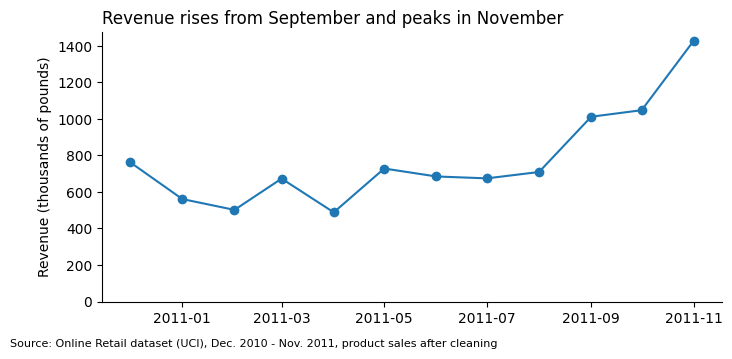

Month
2010-12-01     762.0
2011-01-01     560.7
2011-02-01     501.5
2011-03-01     672.7
2011-04-01     488.0
2011-05-01     727.9
2011-06-01     684.4
2011-07-01     674.1
2011-08-01     708.9
2011-09-01    1011.4
2011-10-01    1047.1
2011-11-01    1428.2


In [17]:
import matplotlib.pyplot as plt

OUT = os.path.join(PROJECT, "outputs")
complete = sales[sales["InvoiceDate"] < "2011-12-01"]            # 12 complete months
monthly = complete.groupby("Month")["Revenue"].sum() / 1000      # thousands of pounds

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(monthly.index, monthly.values, marker="o", color="tab:blue")
ax.set_ylim(0)
ax.set_title("Revenue rises from September and peaks in November", loc="left")
ax.set_ylabel("Revenue (thousands of pounds)")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "Source: Online Retail dataset (UCI), Dec. 2010 - Nov. 2011, product sales after cleaning", fontsize=8)
fig.savefig(os.path.join(OUT, "chart1_monthly_revenue.png"), dpi=150, bbox_inches="tight")
plt.show()
print(monthly.round(1).to_string())

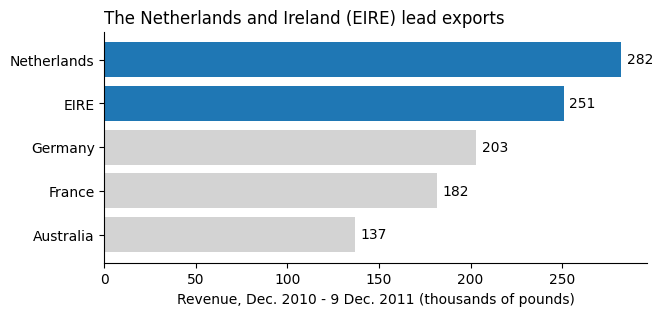

Country
Netherlands    282.2
EIRE           250.8
Germany        203.1
France         181.5
Australia      136.9


In [18]:
#===Chart 2 — where do we sell, outside the United Kingdom?
export = sales[sales["Country"] != "United Kingdom"]
top = export.groupby("Country")["Revenue"].sum().nlargest(5).sort_values() / 1000

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(top.index, top.values, color="lightgray")                 # gray first
ax.barh(top.index[-2:], top.values[-2:], color="tab:blue")        # highlight the two leaders
for y, v in enumerate(top.values):
    ax.text(v + 3, y, f"{v:.0f}", va="center")
ax.set_title("The Netherlands and Ireland (EIRE) lead exports", loc="left")
ax.set_xlabel("Revenue, Dec. 2010 - 9 Dec. 2011 (thousands of pounds)")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(OUT, "chart2_top_export_countries.png"), dpi=150, bbox_inches="tight")
plt.show()
print(top.round(1).sort_values(ascending=False).to_string())

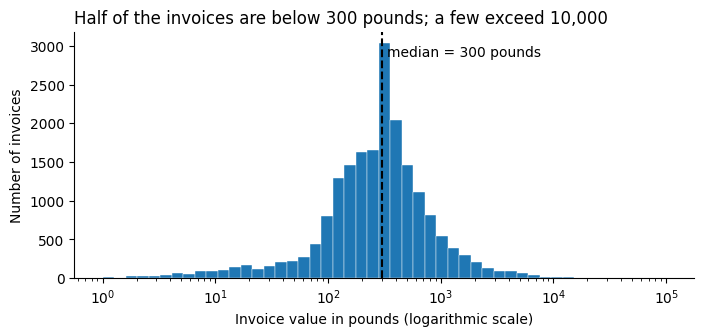

Invoices above 10,000 pounds: 47


In [19]:
#===Chart 3 — how big is an invoice?
import numpy as np

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.logspace(0, 5, 50)                                   # from 1 to 100,000 pounds
ax.hist(invoice_value, bins=bins, color="tab:blue", edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.axvline(invoice_value.median(), color="black", linestyle="--")
ax.text(invoice_value.median() * 1.1, ax.get_ylim()[1] * 0.9, f"median = {invoice_value.median():.0f} pounds")
ax.set_title("Half of the invoices are below 300 pounds; a few exceed 10,000", loc="left")
ax.set_xlabel("Invoice value in pounds (logarithmic scale)")
ax.set_ylabel("Number of invoices")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(OUT, "chart3_invoice_values.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Invoices above 10,000 pounds:", (invoice_value > 10000).sum())

Revenue per weekday (thousands of pounds):
weekday
Monday       1550.0
Tuesday      1893.0
Wednesday    1670.0
Thursday     1958.0
Friday       1435.0
Saturday        0.0
Sunday        761.0


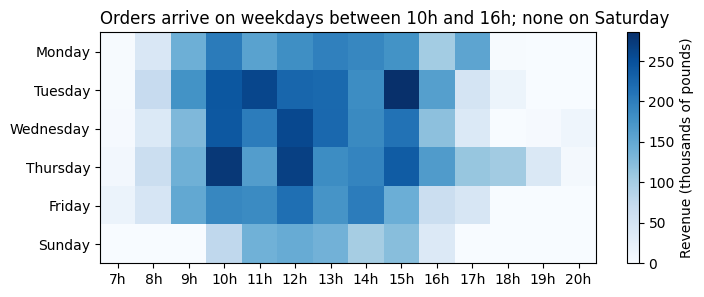

Share of revenue between 10h and 16h: 76%


In [20]:
#===Chart 4 — on which days and at what time do orders arrive?===
t = complete.assign(weekday=complete["InvoiceDate"].dt.day_name(), hour=complete["InvoiceDate"].dt.hour)
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
table = t.pivot_table(index="weekday", columns="hour", values="Revenue", aggfunc="sum").reindex(days) / 1000
print("Revenue per weekday (thousands of pounds):")
print(table.sum(axis=1).round(0).to_string())                  # Saturday: no order at all

shown = table.dropna(how="all").fillna(0)
fig, ax = plt.subplots(figsize=(8, 3))
im = ax.imshow(shown.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(shown.shape[1])); ax.set_xticklabels([f"{h}h" for h in shown.columns])
ax.set_yticks(range(shown.shape[0])); ax.set_yticklabels(shown.index)
ax.set_title("Orders arrive on weekdays between 10h and 16h; none on Saturday", loc="left")
fig.colorbar(im, ax=ax, label="Revenue (thousands of pounds)")
fig.savefig(os.path.join(OUT, "chart4_weekday_hour.png"), dpi=150, bbox_inches="tight")
plt.show()
by_hour = complete.groupby(complete["InvoiceDate"].dt.hour)["Revenue"].sum()
print(f"Share of revenue between 10h and 16h: {by_hour.loc[10:15].sum() / by_hour.sum():.0%}")

In [21]:
#===Customers: recency, frequency, value — and concentration
known = sales.dropna(subset=["CustomerID"])                        # customer analysis: identified customers only
reference_day = sales["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = known.groupby("CustomerID").agg(
    recency=("InvoiceDate", lambda d: (reference_day - d.max()).days),
    frequency=("InvoiceNo", "nunique"),
    monetary=("Revenue", "sum"),
)
print(f"Identified customers: {len(rfm):,}")
print(rfm.median().round(0).to_string())
print(f"Customers with one invoice only: {(rfm['frequency'] == 1).mean():.0%}")
print(f"Revenue from unidentified orders: {1 - known['Revenue'].sum() / sales['Revenue'].sum():.0%}")
rfm.sort_values("monetary", ascending=False).head()

Identified customers: 4,321
recency       51.0
frequency      2.0
monetary     654.0
Customers with one invoice only: 35%
Revenue from unidentified orders: 16%


,recency,frequency,monetary
CustomerID,,,
14646,2,71,277460.42
18102,1,60,259657.30
17450,8,45,189607.53
12415,24,19,123745.68
14911,1,192,121172.12


In [22]:
m = rfm["monetary"].sort_values(ascending=False)
top20 = m.head(int(len(m) * 0.20)).sum() / m.sum()
top1 = m.head(int(len(m) * 0.01)).sum() / m.sum()
print(f"Top 20% of customers: {top20:.0%} of the identified revenue")
print(f"Top  1% of customers ({int(len(m) * 0.01)} customers): {top1:.0%}")

Top 20% of customers: 73% of the identified revenue
Top  1% of customers (43 customers): 30%


In [23]:
cleaning_log.to_csv(os.path.join(OUT, "cleaning_log.csv"), index=False)
monthly.round(1).rename("revenue_k_pounds").to_csv(os.path.join(OUT, "monthly_revenue.csv"))
(sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False) / 1000).round(1).rename("revenue_k_pounds").to_csv(os.path.join(OUT, "revenue_by_country.csv"))
rfm.round(2).to_csv(os.path.join(OUT, "customers_rfm.csv"))
print(sorted(os.listdir(OUT)))

['chart1_monthly_revenue.png', 'chart2_top_export_countries.png', 'chart3_invoice_values.png', 'chart4_weekday_hour.png', 'cleaning_log.csv', 'customers_rfm.csv', 'monthly_revenue.csv', 'revenue_by_country.csv']
